<a href="https://colab.research.google.com/github/LuanaLazzarin/Novo-Lar/blob/main/Conhe%C3%A7a_o_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
O objetivo é aplicar um modelo de Regressão Linear para prever
o valor médio das casas do conjunto de dados Boston Housing.

Será utilizada a variável RM, que representa o número médio de quartos por
moradia, para estimar a variável MEDV, que representa o valor médio das casas.

O desempenho do modelo será avaliado por meio das métricas Erro Quadrático
Médio (MSE) e Coeficiente de Determinação (R²), além da análise gráfica dos
valores reais e previstos.

In [1]:
# Importação das bibliotecas necessárias

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
# Carregamento do conjunto de dados Boston Housing:

dados = fetch_openml(
    name="boston",
    version=1,
    as_frame=True)

# Visualizar as primeiras linhas do conjunto de dados
df = dados.frame
df.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2


Neste experimento, foi escolhida a variável RM como variável independente (X), pois representa o número médio de quartos por moradia.

A variável dependente (Y) será MEDV, que representa o valor médio das casas.

O objetivo é analisar se existe uma relação linear entre o número médio de quartos e o valor das moradias.

In [3]:
# Seleção da variável independente e da variável dependente

X = df[["RM"]]
y = df["MEDV"]

# Exibir algumas observações
print("Variável independente (RM):")
print(X.head())

print("\nVariável dependente (MEDV):")
print(y.head())

Variável independente (RM):
      RM
0  6.575
1  6.421
2  7.185
3  6.998
4  7.147

Variável dependente (MEDV):
0    24.0
1    21.6
2    34.7
3    33.4
4    36.2
Name: MEDV, dtype: float64


Agora dados serão divididos em duas partes: 80% para treinamento e 20% para teste.

O conjunto de treinamento será utilizado para o modelo aprender a relação entre as variáveis. O conjunto de teste será utilizado para avaliar o desempenho do modelo em dados que não foram utilizados durante o treinamento.

In [4]:
# Divisão dos dados em treinamento e teste

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Quantidade de dados para treinamento:", len(X_treino))
print("Quantidade de dados para teste:", len(X_teste))

Quantidade de dados para treinamento: 404
Quantidade de dados para teste: 102


In [5]:
# Criar o modelo de Regressão Linear:
modelo = LinearRegression()

# Treinar o modelo com os dados de treinamento:
modelo.fit(X_treino, y_treino)

# Gerar previsões para os dados de teste:
y_previsto = modelo.predict(X_teste)

# Exibir os coeficientes do modelo:
print("Coeficiente angular:", modelo.coef_[0])
print("Intercepto:", modelo.intercept_)

Coeficiente angular: 9.348301406497727
Intercepto: -36.24631889813795


O desempenho do modelo será avaliado por duas métricas:

- MSE (Erro Quadrático Médio): calcula a média dos erros de previsão elevados ao quadrado. Quanto menor o valor, menores tendem a ser os erros.

- R² (Coeficiente de Determinação): indica quanto da variação da variável dependente é explicada pelo modelo. Quanto mais próximo de 1, melhor o ajuste aos dados avaliados.

In [6]:
# Calcular as métricas de avaliação:
mse = mean_squared_error(y_teste, y_previsto)
r2 = r2_score(y_teste, y_previsto)

print(f"Erro Quadrático Médio (MSE): {mse:.2f}")
print(f"Coeficiente de Determinação (R²): {r2:.4f}")

Erro Quadrático Médio (MSE): 46.14
Coeficiente de Determinação (R²): 0.3708


O gráfico apresentará os valores reais das moradias como pontos e a reta aprendida pelo modelo de Regressão Linear, permitindo observar a tendência dos dados e verificar se a reta representa adequadamente a relação entre o número médio de quartos e o valor das casas.

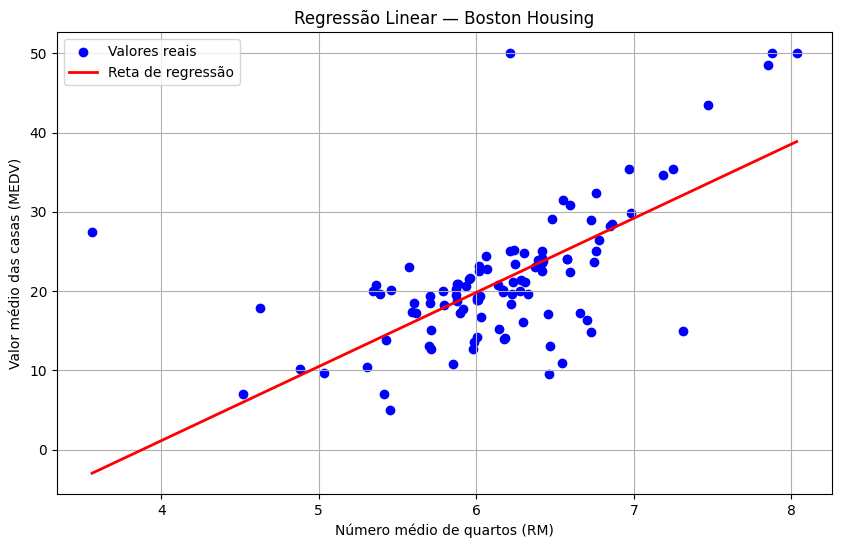

In [7]:
# Organizar os valores de X para desenhar a reta em ordem crescente

ordem = np.argsort(X_teste["RM"].values)

x_ordenado = X_teste["RM"].values[ordem]
y_ordenado = y_previsto[ordem]

# Construir o gráfico
plt.figure(figsize=(10, 6))

# Pontos reais
plt.scatter(
    X_teste["RM"],
    y_teste,
    color="blue",
    label="Valores reais"
)

# Reta prevista pelo modelo
plt.plot(
    x_ordenado,
    y_ordenado,
    color="red",
    linewidth=2,
    label="Reta de regressão"
)

plt.title("Regressão Linear — Boston Housing")
plt.xlabel("Número médio de quartos (RM)")
plt.ylabel("Valor médio das casas (MEDV)")
plt.legend()
plt.grid(True)

plt.show()

Interpretação dos resultados:

O que significa o MSE obtido?

O Erro Quadrático Médio representa a média dos erros de previsão elevados ao quadrado. O valor obtido foi de **[INSERIR O MSE CALCULADO]**. Quanto menor o MSE, menor tende a ser a diferença entre os valores reais e os valores previstos pelo modelo.

Como o erro é elevado ao quadrado, sua unidade também fica ao quadrado em relação à unidade utilizada para representar os valores das casas.

O que representa o R²?

O Coeficiente de Determinação obtido foi de **[INSERIR O R² CALCULADO]**. Essa métrica indica a proporção da variação dos valores das casas que é explicada pelo modelo no conjunto de teste.

Um R² próximo de 1 indica maior capacidade explicativa, enquanto um valor próximo de 0 indica pouca capacidade explicativa em relação à média dos valores observados.

O modelo explica bem a variação dos dados?

A qualidade do modelo deve ser avaliada considerando o valor do R², o MSE e a distribuição dos pontos no gráfico.

Se os pontos estiverem próximos da reta e o R² for relativamente alto, o modelo apresenta um ajuste melhor. Se os pontos estiverem muito dispersos e o R² for baixo, a variável RM, sozinha, não será suficiente para explicar grande parte da variação dos valores das casas.

Por fim, como foi utilizada apenas uma variável independente, outras características das moradias também podem influenciar os preços e não são consideradas nesta análise.